In [44]:
from pathlib import Path

from bst_bev.nuscenes.context import NuScenesSampleContext
from bst_bev.evaluation.retrieval import BSTRetrievalEvaluator


PROJECT_ROOT = Path.cwd()

if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

DATAROOT = PROJECT_ROOT / "data" / "nuscenes"

In [45]:
context = NuScenesSampleContext.from_scene_index(
    dataroot=DATAROOT,
    scene_index=0,
)

print("Scene:", context.scene["name"])
print("Location:", context.location)
print(
    "Ego:",
    context.ego_x,
    context.ego_y,
)

Scene: scene-0061
Location: singapore-onenorth
Ego: 411.3039349319818 1180.8903791765097


In [46]:
evaluator = BSTRetrievalEvaluator(
    context=context,
    radius=30.0,
    query_step=2.0,
)

results = evaluator.sweep(
    range(18, 40)
)

In [47]:
for result in results:
    print(
        f"z={result.zoom:2d} | "
        f"recall={result.recall:.3f} | "
        f"precision={result.precision:.3f} | "
        f"TP={result.true_positive:2d} | "
        f"FP={result.false_positive:2d} | "
        f"FN={result.false_negative:2d}"
    )

z=18 | recall=1.000 | precision=0.105 | TP= 4 | FP=34 | FN= 0
z=19 | recall=1.000 | precision=0.286 | TP= 4 | FP=10 | FN= 0
z=20 | recall=1.000 | precision=0.333 | TP= 4 | FP= 8 | FN= 0
z=21 | recall=1.000 | precision=1.000 | TP= 4 | FP= 0 | FN= 0
z=22 | recall=1.000 | precision=1.000 | TP= 4 | FP= 0 | FN= 0
z=23 | recall=1.000 | precision=1.000 | TP= 4 | FP= 0 | FN= 0
z=24 | recall=1.000 | precision=1.000 | TP= 4 | FP= 0 | FN= 0
z=25 | recall=0.750 | precision=1.000 | TP= 3 | FP= 0 | FN= 1
z=26 | recall=0.000 | precision=0.000 | TP= 0 | FP= 0 | FN= 4
z=27 | recall=0.000 | precision=0.000 | TP= 0 | FP= 0 | FN= 4
z=28 | recall=0.000 | precision=0.000 | TP= 0 | FP= 0 | FN= 4
z=29 | recall=0.000 | precision=0.000 | TP= 0 | FP= 0 | FN= 4
z=30 | recall=0.000 | precision=0.000 | TP= 0 | FP= 0 | FN= 4
z=31 | recall=0.000 | precision=0.000 | TP= 0 | FP= 0 | FN= 4
z=32 | recall=0.000 | precision=0.000 | TP= 0 | FP= 0 | FN= 4
z=33 | recall=0.000 | precision=0.000 | TP= 0 | FP= 0 | FN= 4
z=34 | r

In [48]:
import pandas as pd


df = pd.DataFrame(
    result.to_dict()
    for result in results
)

df

,zoom,bst_retrieved,ground_truth,correct,true_positive,false_positive,false_negative,precision,recall
0,18,38,4,4,4,34,0,0.105263,1.00
1,19,14,4,4,4,10,0,0.285714,1.00
2,20,12,4,4,4,8,0,0.333333,1.00
3,21,4,4,4,4,0,0,1.000000,1.00
4,22,4,4,4,4,0,0,1.000000,1.00
5,23,4,4,4,4,0,0,1.000000,1.00
6,24,4,4,4,4,0,0,1.000000,1.00
7,25,3,4,3,3,0,1,1.000000,0.75
8,26,0,4,0,0,0,4,0.000000,0.00
9,27,0,4,0,0,0,4,0.000000,0.00


<Axes: xlabel='zoom'>

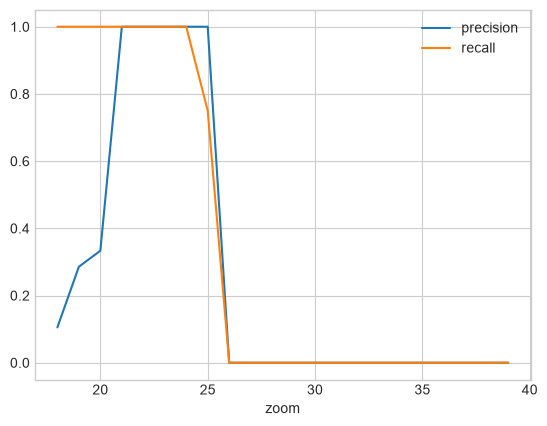

In [49]:
df.plot(
    x="zoom",
    y=[
        "precision",
        "recall",
    ],
)